# DNN Assignment 2 - Problem 2: Transformer from scratch
Run top to bottom. Data goes to `../data` (shared with Problem 1), figures to `figures/`, results to `../results.csv`.

`scaled_dot_product_attention`, `MultiHeadAttention` and `EncoderBlock` are implemented from scratch below (no `nn.MultiheadAttention` / `nn.Transformer*`).

**Assumptions:** Task A uses 2 encoder layers, 4 heads, patch size 8, AdamW lr 5e-4; Task B uses one seed,
AdamW lr 1e-3 with warmup + cosine decay, top-k = 40, sinusoidal positions; no key-value cache (bonus skipped).

In [16]:
import os
print("cwd:", os.getcwd())
print("data dir:", os.path.abspath("../data"))
print("HAR present:", os.path.isdir("../data/har/UCI HAR Dataset"))
print("results.csv present:", os.path.exists("../results.csv"))

cwd: /content
data dir: /data
HAR present: True
results.csv present: True


In [15]:
import os, time, math, random, zipfile, urllib.request
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# ---------------- CONFIG ----------------
STUDENT_ID = "2026AK05289"
D_MODEL, N_HEADS, N_LAYERS, D_FF = 128, 4, 4, 512      # Task B / block test sizes from the assignment
SEEDS      = [0, 1, 2]         # Seeds (Task A)
CTX        = 128
STEPS_LM   = 5000              # language-model training steps (main + ablations)
BATCH_LM   = 64
EPOCHS_A   = 40
BATCH_A, LR_A = 64, 5e-4
LAYERS_A   = 2
TOP_K      = 40
QUICK      = False             # True = tiny debug run
# ------------------------------------------------------------------------------
if QUICK:
    STEPS_LM, EPOCHS_A, SEEDS = 60, 2, SEEDS[:1]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)
os.makedirs("figures", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
def n_params(m): return sum(p.numel() for p in m.parameters())

COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse","params",
        "sec_per_epoch","val_loss_nats","bits_per_char","notes"]
RESULTS_CSV = "../results.csv"
def reset_results(prefix):
    if os.path.exists(RESULTS_CSV):
        df = pd.read_csv(RESULTS_CSV)
        df[~df["problem"].astype(str).str.startswith(prefix)].to_csv(RESULTS_CSV, index=False)
def log_result(**kw):
    row = {c: kw.get(c, "") for c in COLS}
    pd.DataFrame([row], columns=COLS).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
reset_results("P2")

device: cuda | torch 2.14.1+cu130


## Task 1 - Scaled dot-product attention
Contract used by every later cell: `q, k, v` have shape `(..., T, d_k)` (any number of leading dims, e.g. `(B, heads)`);
`mask` is a **bool** tensor broadcastable to `(..., Tq, Tk)` with `True = may attend`; return `(out, weights)` with
`out: (..., Tq, d_v)` and `weights: (..., Tq, Tk)`. Formula: `softmax(q k^T / sqrt(d_k)) v`.

In [17]:
def scaled_dot_product_attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))          # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))              # masked keys get zero weight after softmax
    w = F.softmax(scores, dim=-1)
    return w @ v, w

# ---- unit tests (directly after the function) ----
torch.manual_seed(0)
q, k, v = torch.randn(2, 4, 6, 16), torch.randn(2, 4, 6, 16), torch.randn(2, 4, 6, 16)   # (B, heads, T, d_k)
out, w = scaled_dot_product_attention(q, k, v)
assert out.shape == (2, 4, 6, 16) and w.shape == (2, 4, 6, 6)
assert torch.allclose(w.sum(-1), torch.ones(2, 4, 6), atol=1e-5), "each row of weights must sum to 1"
assert (out - F.scaled_dot_product_attention(q, k, v)).abs().max() < 1e-5, "must match the library version"
causal = torch.tril(torch.ones(6, 6, dtype=torch.bool))
out_c, w_c = scaled_dot_product_attention(q, k, v, causal)
assert w_c.masked_fill(causal, 0).abs().max() < 1e-9, "causal mask must give zero weight to future positions"
assert torch.allclose(w_c.sum(-1), torch.ones(2, 4, 6), atol=1e-5)
assert (out_c - F.scaled_dot_product_attention(q, k, v, attn_mask=causal)).abs().max() < 1e-5
print("attention tests passed")

attention tests passed


In [18]:
# ---- 3-token example: compute by code, then compared with hand calculation ----
Qx = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
Kx = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
Vx = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
ox, wx = scaled_dot_product_attention(Qx, Kx, Vx)
print("weights:\n", wx, "\noutput:\n", ox)
HAND_WEIGHTS = torch.tensor([[0.4011, 0.1978, 0.4011],
                             [0.1978, 0.4011, 0.4011],
                             [0.2483, 0.2483, 0.5035]])
HAND_OUT = torch.tensor([[3.0000, 4.0000],
                         [3.4066, 4.4066],
                         [3.5105, 4.5105]])
if HAND_WEIGHTS is not None:
    assert torch.allclose(wx, HAND_WEIGHTS, atol=1e-3) and torch.allclose(ox, HAND_OUT, atol=1e-3)
    print("hand calculation agrees with code")

weights:
 tensor([[0.4011, 0.1978, 0.4011],
        [0.1978, 0.4011, 0.4011],
        [0.2483, 0.2483, 0.5035]]) 
output:
 tensor([[3.0000, 4.0000],
        [3.4067, 4.4067],
        [3.5105, 4.5105]])
hand calculation agrees with code


## Task 2 - Multi-head attention and pre-LN encoder block
Contract used later:
* `MultiHeadAttention(d, n_heads, dropout=0.0)`: `nn.Linear(d, d)` for `W_Q, W_K, W_V, W_O` **with bias**; `forward(x, mask=None)`, `x: (B,T,d) -> (B,T,d)`;
  reshape `(B,T,d) -> (B,h,T,d/h)`, call your attention, merge heads back; **store `self.attn_weights = w.detach()` of shape (B,h,T,T)** (used for heatmaps).
* `EncoderBlock(d, n_heads, d_ff=None, dropout=0.0)` (d_ff defaults to 4d), pre-LayerNorm: `x = x + mha(ln1(x), mask)` (dropout inside the MHA output), `x = x + drop(ff(ln2(x)))`,
  `ff = Linear(d,d_ff) -> GELU -> Linear(d_ff,d)`. Name the attention submodule **`self.mha`**; `forward(x, mask=None)`.

In [19]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, n_heads, dropout=0.0):
        super().__init__()
        assert d % n_heads == 0, "d must be divisible by the number of heads"
        self.h, self.dk = n_heads, d // n_heads
        self.W_Q, self.W_K, self.W_V, self.W_O = (nn.Linear(d, d) for _ in range(4))
        self.drop = nn.Dropout(dropout)
        self.attn_weights = None
    def forward(self, x, mask=None):
        B, T, d = x.shape
        split = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)    # (B,T,d) -> (B,h,T,dk)
        out, w = scaled_dot_product_attention(split(self.W_Q(x)), split(self.W_K(x)), split(self.W_V(x)), mask)
        self.attn_weights = w.detach()                                      # (B,h,T,T), for heatmaps
        return self.drop(self.W_O(out.transpose(1, 2).reshape(B, T, d)))   # merge heads, output projection

class EncoderBlock(nn.Module):
    def __init__(self, d, n_heads, d_ff=None, dropout=0.0):
        super().__init__()
        d_ff = d_ff or 4 * d
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.mha = MultiHeadAttention(d, n_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        x = x + self.mha(self.ln1(x), mask)              # pre-LN; dropout is applied inside the MHA output
        return x + self.drop(self.ff(self.ln2(x)))

class SinusoidalPE(nn.Module):
    """Fixed sinusoidal positional encoding: PE[pos,2i]=sin(pos/10000^(2i/d)), PE[pos,2i+1]=cos(...)."""
    def __init__(self, d, max_len=1024):
        super().__init__()
        pe = torch.zeros(max_len, d)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)
    def forward(self, x):                      # x: (B,T,d)
        return x + self.pe[: x.size(1)]

# ---- tests: shapes, causality of the block, parameter count ----
d, h, d_ff = D_MODEL, N_HEADS, D_FF
blk = EncoderBlock(d, h, d_ff, 0.0).eval()
x = torch.randn(3, 10, d)
assert blk(x).shape == x.shape
assert blk.mha.attn_weights.shape == (3, h, 10, 10)
cm = torch.tril(torch.ones(10, 10, dtype=torch.bool))
x2 = x.clone(); x2[:, 7:] = torch.randn(3, 3, d)                # change only future tokens
assert torch.allclose(blk(x, cm)[:, :7], blk(x2, cm)[:, :7], atol=1e-5), "causal block must ignore future tokens"
assert torch.allclose(SinusoidalPE(d)(torch.zeros(1, 4, d))[0, 0, :4], torch.tensor([0., 1., 0., 1.]))

weights_only = 4 * d * d + 2 * d * d_ff                      # W_Q,W_K,W_V,W_O + two FFN matrices
biases = 4 * d + (d_ff + d)                                    # MHA biases + FFN biases
layernorm = 2 * (2 * d)                                        # two LayerNorms, weight+bias each
print(f"weights {weights_only}  + biases {biases} + LayerNorm {layernorm} = {weights_only + biases + layernorm}; counted: {n_params(blk)}")
assert weights_only == 196_608 and n_params(blk) == weights_only + biases + layernorm
print("encoder-block tests passed")

weights 196608  + biases 1152 + LayerNorm 512 = 198272; counted: 198272
encoder-block tests passed


## Shared data: UCI HAR (as in Problem 1)

In [20]:
DATA = "../data"
HAR_ROOT = f"{DATA}/har/UCI HAR Dataset"
CHANNELS = ["body_acc_x","body_acc_y","body_acc_z","body_gyro_x","body_gyro_y","body_gyro_z",
            "total_acc_x","total_acc_y","total_acc_z"]

def download_har():
    if os.path.isdir(HAR_ROOT): return
    os.makedirs(f"{DATA}/har", exist_ok=True)
    urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", f"{DATA}/har.zip")
    zipfile.ZipFile(f"{DATA}/har.zip").extractall(f"{DATA}/har")
    inner = f"{DATA}/har/UCI HAR Dataset.zip"
    if os.path.exists(inner): zipfile.ZipFile(inner).extractall(f"{DATA}/har")
    assert os.path.isdir(HAR_ROOT)

def load_har_split(split):
    X = np.stack([np.loadtxt(f"{HAR_ROOT}/{split}/Inertial Signals/{c}_{split}.txt") for c in CHANNELS], axis=-1).astype(np.float32)
    y = np.loadtxt(f"{HAR_ROOT}/{split}/y_{split}.txt", dtype=int) - 1
    s = np.loadtxt(f"{HAR_ROOT}/{split}/subject_{split}.txt", dtype=int)
    return X, y, s

download_har()
X_TR_ALL, Y_TR_ALL, S_TR_ALL = load_har_split("train"); X_TE, Y_TE, S_TE = load_har_split("test")

def get_har(seed):
    """Identical to Problem 1: 4 of 21 training subjects held out; train-only per-channel statistics."""
    rng = np.random.default_rng(seed)
    is_val = np.isin(S_TR_ALL, rng.choice(np.unique(S_TR_ALL), 4, replace=False))
    Xtr, ytr, Xva, yva = X_TR_ALL[~is_val], Y_TR_ALL[~is_val], X_TR_ALL[is_val], Y_TR_ALL[is_val]
    mean, std = Xtr.mean(axis=(0, 1), keepdims=True), Xtr.std(axis=(0, 1), keepdims=True) + 1e-8
    f = lambda a, b: (torch.tensor(((a - mean) / std).astype(np.float32)).to(device), torch.tensor(b).long().to(device))
    return f(Xtr, ytr), f(Xva, yva), f(X_TE, Y_TE)

## Task A - Encoder classifier on HAR (patches of 8 steps + CLS token; positional ablation)

In [21]:
class HARTransformer(nn.Module):
    def __init__(self, pos="sinusoidal", d=D_MODEL, n_heads=N_HEADS, n_layers=LAYERS_A, patch=8,
                 d_in=9, T=128, n_cls=6, dropout=0.1):
        super().__init__()
        assert T % patch == 0
        self.patch, n_tok = patch, T // patch
        self.embed = nn.Linear(patch * d_in, d)
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.pos_kind = pos
        if pos == "sinusoidal": self.pos = SinusoidalPE(d, n_tok + 1)
        elif pos == "learned":  self.pos = nn.Parameter(torch.randn(1, n_tok + 1, d) * 0.02)
        elif pos != "none":     raise ValueError(pos)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, 4 * d, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d); self.head = nn.Linear(d, n_cls)
    def forward(self, x):                                    # x: (B,128,9)
        B, T, C = x.shape
        x = self.embed(x.reshape(B, T // self.patch, self.patch * C))   # (B,16,d)
        x = torch.cat([self.cls.expand(B, -1, -1), x], 1)                # (B,17,d) with CLS first
        if self.pos_kind == "sinusoidal": x = self.pos(x)
        elif self.pos_kind == "learned":  x = x + self.pos
        x = self.drop(x)
        for b in self.blocks: x = b(x)
        return self.head(self.ln(x[:, 0]))                               # classify from CLS

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval(); return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])

def train_har_tf(pos, seed, epochs=None):
    epochs = epochs or EPOCHS_A
    set_seed(seed)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = get_har(seed)
    model = HARTransformer(pos).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR_A, weight_decay=0.01)
    best_val, best_state, times = -1, None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time(); perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), BATCH_A):
            idx = perm[i:i + BATCH_A]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sync(); times.append(time.time() - t0)
        va = (predict(model, Xva) == yva).float().mean().item()
        if va > best_val: best_val, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    pred, y = predict(model, Xte).cpu().numpy(), yte.cpu().numpy()
    return dict(test_acc=float((pred == y).mean()), macro_f1=float(f1_score(y, pred, average="macro")),
                params=n_params(model), sec_per_epoch=float(np.mean(times)))

for pos in ["none", "sinusoidal", "learned"]:
    for seed in SEEDS:
        r = train_har_tf(pos, seed)
        log_result(problem="P2-A", model=f"enc-{pos}", seed=seed, seq_len=128, test_acc=r["test_acc"], macro_f1=r["macro_f1"],
                   params=r["params"], sec_per_epoch=r["sec_per_epoch"], notes=f"d={D_MODEL};heads={N_HEADS};layers={LAYERS_A};patch=8;epochs={EPOCHS_A}")
        print(f"pos={pos:10s} seed {seed}: acc {r['test_acc']:.4f}  F1 {r['macro_f1']:.4f}")

df = pd.read_csv(RESULTS_CSV)
tabA = df[df.problem == "P2-A"].groupby("model").agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
        f1_mean=("macro_f1", "mean"), params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean")).round(4)
print(tabA)
p1 = df[df.problem == "P1-HAR"]                                   # Problem 1 results
if len(p1):
    print("\nProblem 1 for comparison:\n", p1.groupby("model").agg(acc_mean=("test_acc", "mean"), acc_std=("test_acc", "std"),
          params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean")).round(4))
else:
    print("\n(no P1-HAR rows in ../results.csv yet - run Problem 1 first for the comparison)")

pos=none       seed 0: acc 0.9467  F1 0.9462
pos=none       seed 1: acc 0.9274  F1 0.9288
pos=none       seed 2: acc 0.9399  F1 0.9400
pos=sinusoidal seed 0: acc 0.9315  F1 0.9309
pos=sinusoidal seed 1: acc 0.9023  F1 0.9011
pos=sinusoidal seed 2: acc 0.9053  F1 0.9050
pos=learned    seed 0: acc 0.9365  F1 0.9358
pos=learned    seed 1: acc 0.9114  F1 0.9111
pos=learned    seed 2: acc 0.9287  F1 0.9284
                acc_mean  acc_std  f1_mean  params  sec_per_epoch
model                                                            
enc-learned       0.9256   0.0129   0.9251  409222         0.7946
enc-none          0.9380   0.0098   0.9383  407046         1.2911
enc-sinusoidal    0.9130   0.0160   0.9123  407046         0.7980

Problem 1 for comparison:
        acc_mean  acc_std  params  sec_per_epoch
model                                          
gru      0.8955   0.0068   14790         0.2607
lstm     0.8990   0.0190   19590         0.3256
rnn      0.8549   0.0081    5190         0.26

## Task B - Character-level causal language model (Tiny Shakespeare)

1,115,394 chars, vocab 65, train 1,003,854, val 111,540, uniform loss ln(65) = 4.174
{'step': 250, 'train': 2.76090087890625, 'val': 2.3054854035377503}
{'step': 500, 'train': 2.167057255744934, 'val': 2.061435216665268}
{'step': 750, 'train': 1.9380230951309203, 'val': 1.9297325402498244}
{'step': 1000, 'train': 1.7944927654266358, 'val': 1.8375458806753158}
{'step': 1250, 'train': 1.7010992774963378, 'val': 1.7794179886579513}
{'step': 1500, 'train': 1.6353485527038574, 'val': 1.7369241774082185}
{'step': 1750, 'train': 1.5859691958427429, 'val': 1.6947132468223571}
{'step': 2000, 'train': 1.5526968421936036, 'val': 1.6683953136205674}
{'step': 2250, 'train': 1.5207616448402406, 'val': 1.6523106098175049}
{'step': 2500, 'train': 1.4982647161483764, 'val': 1.6339757859706878}
{'step': 2750, 'train': 1.4761083822250367, 'val': 1.6211893081665039}
{'step': 3000, 'train': 1.459657576084137, 'val': 1.6103543102741242}
{'step': 3250, 'train': 1.445997211933136, 'val': 1.6030998975038528}
{

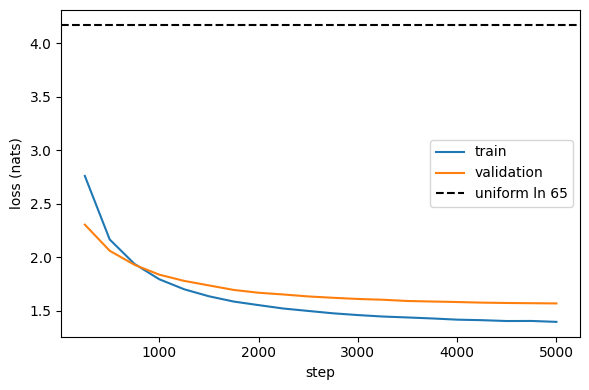

In [22]:
os.makedirs(DATA, exist_ok=True)
TXT = f"{DATA}/tinyshakespeare.txt"
if not os.path.exists(TXT):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", TXT)
text = open(TXT, encoding="utf-8").read()
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
assert V == 65, V
data = torch.tensor(encode(text), dtype=torch.long)
n_tr = int(0.9 * len(data)); train_data, val_data = data[:n_tr].to(device), data[n_tr:].to(device)   # first 90% / last 10%, no shuffling
print(f"{len(text):,} chars, vocab {V}, train {len(train_data):,}, val {len(val_data):,}, uniform loss ln(65) = {math.log(65):.3f}")

def get_batch(split, ctx=CTX, bs=BATCH_LM, gen=None):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - ctx - 1, (bs,), device="cpu", generator=gen).to(device)
    x = torch.stack([d[i:i + ctx] for i in ix]); y = torch.stack([d[i + 1:i + ctx + 1] for i in ix])
    return x, y                                              # (bs,ctx) each; y is x shifted by one

class CharLM(nn.Module):
    def __init__(self, vocab=V, d=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS, dropout=0.1, use_mask=True, max_len=1024):
        super().__init__()
        self.tok = nn.Embedding(vocab, d); self.pos = SinusoidalPE(d, max_len); self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d, n_heads, 4 * d, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d); self.head = nn.Linear(d, vocab)
        self.use_mask = use_mask
    def forward(self, idx, targets=None):
        B, T = idx.shape
        mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=idx.device)) if self.use_mask else None
        x = self.drop(self.pos(self.tok(idx)))              # (B,T,d)
        for b in self.blocks: x = b(x, mask)
        logits = self.head(self.ln_f(x))                    # (B,T,V)
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, V), targets.reshape(-1))
        return logits, loss

@torch.no_grad()
def eval_loss(model, split="val", n_batches=40, force_mask=None):
    model.eval(); old = model.use_mask
    if force_mask is not None: model.use_mask = force_mask
    g = torch.Generator().manual_seed(123); tot = 0.0
    for _ in range(n_batches):
        x, y = get_batch(split, gen=g); tot += model(x, y)[1].item()
    model.use_mask = old
    return tot / n_batches

def train_lm(n_heads=N_HEADS, use_mask=True, steps=None, seed=0, lr=1e-3, eval_every=250, verbose=True):
    steps = steps or STEPS_LM
    set_seed(seed)
    model = CharLM(n_heads=n_heads, use_mask=use_mask).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    warm = max(1, steps // 25)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1, s / steps)))))
    hist, run, cnt = [], 0.0, 0
    for step in range(1, steps + 1):
        model.train(); x, y = get_batch("train")
        _, loss = model(x, y); opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        run += loss.item(); cnt += 1
        if step % eval_every == 0 or step == steps:
            rec = dict(step=step, train=run / cnt, val=eval_loss(model, force_mask=True if use_mask else None))
            if not use_mask: rec["val_causal"] = eval_loss(model, force_mask=True)    # honest evaluation of a model trained without a mask
            hist.append(rec); run, cnt = 0.0, 0
            if verbose: print(rec)
    return model, hist

model_lm, hist_lm = train_lm()
val_nats = eval_loss(model_lm, n_batches=100)
bpc = val_nats / math.log(2)
print(f"final val loss {val_nats:.4f} nats = {bpc:.4f} bits/char; params {n_params(model_lm):,}")
log_result(problem="P2-B", model="causal-LM", seed=0, seq_len=CTX, params=n_params(model_lm), val_loss_nats=val_nats, bits_per_char=bpc,
           notes=f"d={D_MODEL};heads={N_HEADS};layers={N_LAYERS};steps={STEPS_LM};batch={BATCH_LM}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([h["step"] for h in hist_lm], [h["train"] for h in hist_lm], label="train")
ax.plot([h["step"] for h in hist_lm], [h["val"] for h in hist_lm], label="validation")
ax.axhline(math.log(65), color="k", ls="--", label="uniform ln 65")
ax.set_xlabel("step"); ax.set_ylabel("loss (nats)"); ax.legend(); plt.tight_layout()
plt.savefig("figures/lm_learning_curve.png", dpi=150); plt.show()

In [23]:
@torch.no_grad()
def generate(model, n=500, temperature=1.0, top_k=TOP_K, prompt="\n", ctx=CTX):
    model.eval()
    idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        logits, _ = model(idx[:, -ctx:])
        logits = logits[:, -1] / temperature
        if top_k:
            kth = torch.topk(logits, top_k).values[:, [-1]]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        idx = torch.cat([idx, torch.multinomial(F.softmax(logits, -1), 1)], 1)
    return decode(idx[0, len(prompt):].tolist())

samples = {}
with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for T_ in [0.2, 0.8, 1.5]:
        set_seed(0); samples[T_] = generate(model_lm, 500, T_)
        f.write(f"===== temperature {T_} (top-k {TOP_K}, 500 characters) =====\n{samples[T_]}\n\n")
        print(f"----- temperature {T_} -----\n{samples[T_][:300]}\n")

----- temperature 0.2 -----
And the present of the best of the world of the world
And the world of the prove of the world of the world.

LEONTES:
I would the sea thing of the world of the world.

KING RICHARD III:
What is the world the face of the world of the first.

GLOUCESTER:
A pray that words the world of the common of th

----- temperature 0.8 -----
As I have seem a point.

CORIOLANUS:
But in the mean;
And by what we have been to death.

MENENIUS:
This is the shanks of the torn; the was friar,
If your servant thus nature that he dold and city
Upon of thee! will with were perjoice.

CLARENCE:
I was your heaven.

ISABELLA:
O for my husband,
He ar

----- temperature 1.5 -----
Put you? heavy Clifiul! shut you caith.

Nurging Man;
Agarer'd Gruperting by foul derious greats. looking
match sheaves content rany remed in a gail.

GLOUCESTER:
Nay, get! Stad umgries? was, citiflled, folld,
Which wrought and less help mldninglows:
Let praMe Calle, falseSe how our dear.
Rercifford



## Analysis (a) - Attention heatmaps for two heads on one sentence

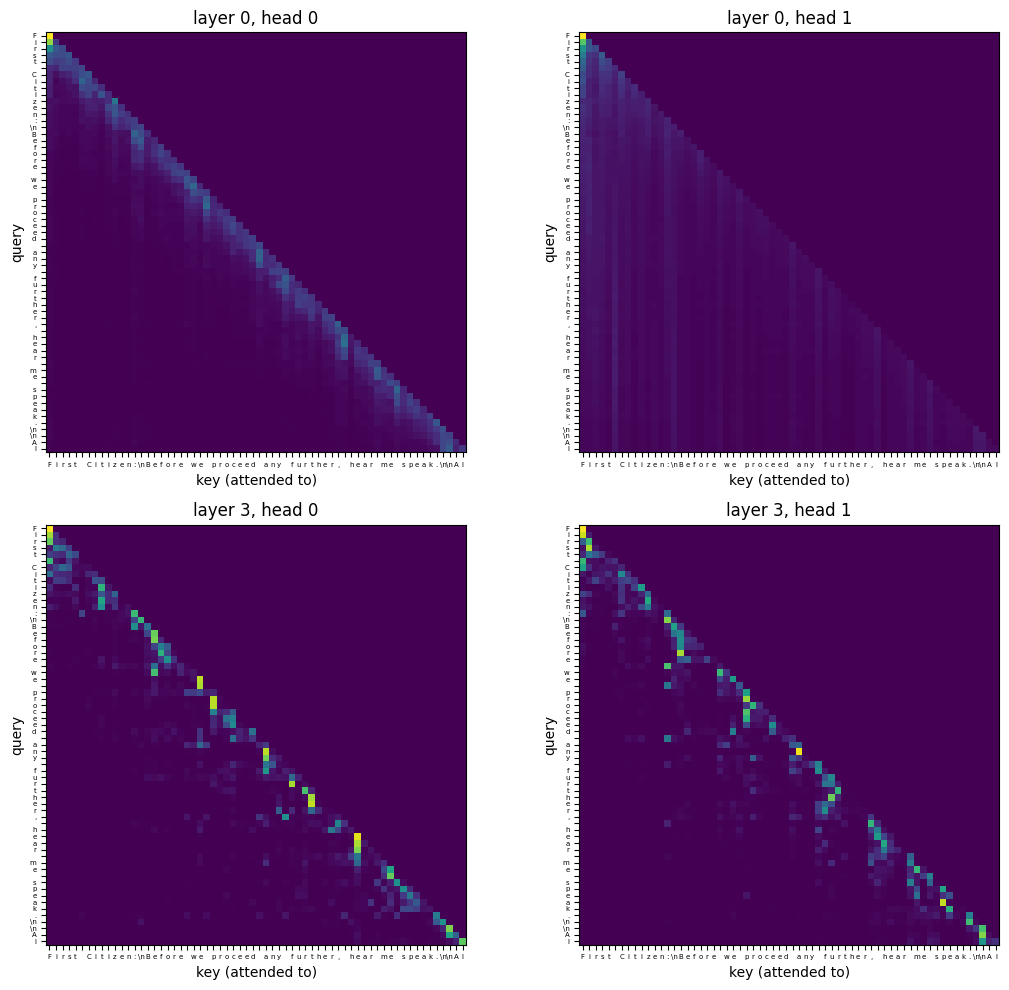

In [30]:
sentence = text[:64]                                         # "First Citizen:\nBefore we proceed any further, hear me speak."
ids = torch.tensor([encode(sentence)], device=device)
model_lm.eval()
with torch.no_grad(): model_lm(ids)
labels = [c.replace("\n", "\\n") for c in sentence]
picks = [(0, 0), (0, 1), (N_LAYERS - 1, 0), (N_LAYERS - 1, 1)]   # (layer, head)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (L, hd) in zip(axes.ravel(), picks):
    A = model_lm.blocks[L].mha.attn_weights[0, hd].cpu().numpy()      # (T,T): row = query, col = key
    ax.imshow(A, cmap="viridis"); ax.set_title(f"layer {L}, head {hd}")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=5); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=5)
    ax.set_xlabel("key (attended to)"); ax.set_ylabel("query")
plt.tight_layout(); plt.savefig("figures/attention_heatmaps.png", dpi=150); plt.show()

## Analysis (b) - Heads = 1, 4, 8 at fixed d = 128

heads=1: val 1.5646 nats (2.2572 bpc)
heads=4: val 1.5604 nats (2.2511 bpc)
heads=8: val 1.5658 nats (2.2590 bpc)


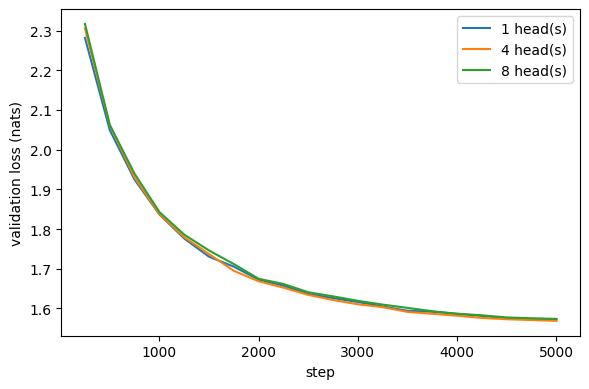

In [24]:
head_results = {N_HEADS: (hist_lm, val_nats)}
for nh in [1, 8]:
    m, hs = train_lm(n_heads=nh, verbose=False)
    head_results[nh] = (hs, eval_loss(m, n_batches=100))
for nh in sorted(head_results):
    v = head_results[nh][1]
    log_result(problem="P2-heads", model=f"LM-{nh}heads", seed=0, seq_len=CTX, val_loss_nats=v, bits_per_char=v / math.log(2),
               notes=f"heads={nh};d={D_MODEL};steps={STEPS_LM}")
    print(f"heads={nh}: val {v:.4f} nats ({v / math.log(2):.4f} bpc)")
fig, ax = plt.subplots(figsize=(6, 4))
for nh in sorted(head_results):
    hs = head_results[nh][0]; ax.plot([h["step"] for h in hs], [h["val"] for h in hs], label=f"{nh} head(s)")
ax.set_xlabel("step"); ax.set_ylabel("validation loss (nats)"); ax.legend(); plt.tight_layout()
plt.savefig("figures/heads_ablation.png", dpi=150); plt.show()

## Analysis (c) - Remove the causal mask

no-mask model: train 0.0160 | val (unmasked) 0.0159 | val (causal, honest) 12.8371


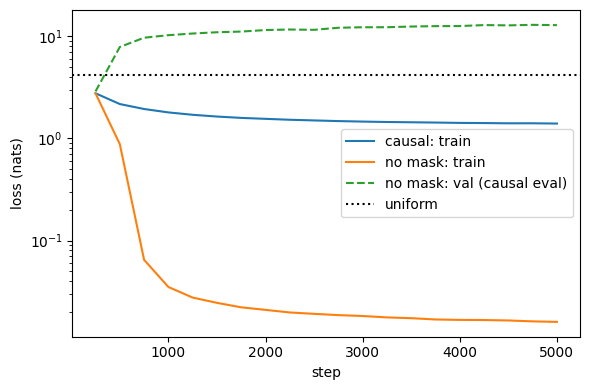

--- generation from the no-mask model (temperature 0.8) ---
 PPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPEPPPPPEPPPPPPPPPPPPPEPPPPPPNPEPPPPEPPPPEPPPPEPPPPPEPPEPPEPEPEPPUPEPPPEPEPPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPTEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPEPE


In [25]:
model_nm, hist_nm = train_lm(use_mask=False, verbose=False)
v_nomask_eval = eval_loss(model_nm, n_batches=100, force_mask=False)      # sees the future: meaningless as a language-model score
v_causal_eval = eval_loss(model_nm, n_batches=100, force_mask=True)       # what generation actually looks like
print(f"no-mask model: train {hist_nm[-1]['train']:.4f} | val (unmasked) {v_nomask_eval:.4f} | val (causal, honest) {v_causal_eval:.4f}")
log_result(problem="P2-nomask", model="LM-no-mask", seed=0, seq_len=CTX, val_loss_nats=v_causal_eval, bits_per_char=v_causal_eval / math.log(2),
           notes=f"trained without mask; unmasked val={v_nomask_eval:.4f}; final train={hist_nm[-1]['train']:.4f}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([h["step"] for h in hist_lm], [h["train"] for h in hist_lm], label="causal: train")
ax.plot([h["step"] for h in hist_nm], [h["train"] for h in hist_nm], label="no mask: train")
ax.plot([h["step"] for h in hist_nm], [h["val_causal"] for h in hist_nm], "--", label="no mask: val (causal eval)")
ax.axhline(math.log(65), color="k", ls=":", label="uniform"); ax.set_yscale("log")
ax.set_xlabel("step"); ax.set_ylabel("loss (nats)"); ax.legend(); plt.tight_layout()
plt.savefig("figures/no_mask.png", dpi=150); plt.show()
set_seed(0); print("--- generation from the no-mask model (temperature 0.8) ---\n", generate(model_nm, 300, 0.8))

## Analysis (d) - Time and memory against context length (64, 128, 256, 512)

   ctx  model_ms  model_MB  attn_ms  attn_MB
0   64     11.74    289.76     1.23   249.96
1  128     12.58    338.87     1.19   263.83
2  256     20.12    472.99     2.37   314.58
3  512     60.21    921.49     9.23   512.95


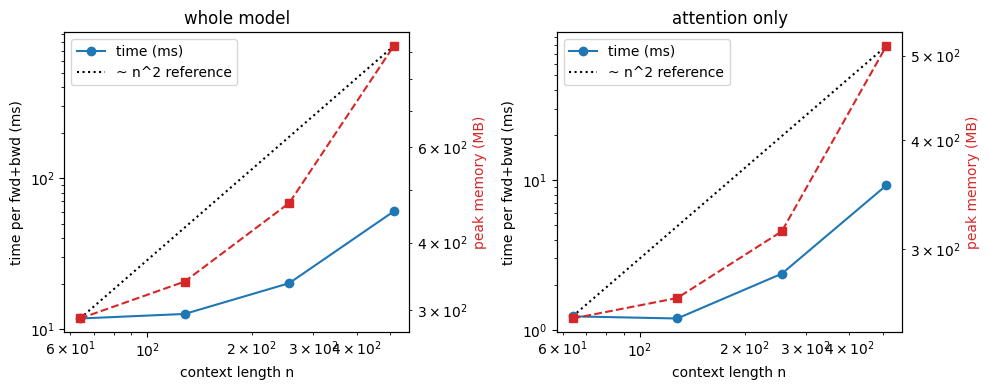

problem
P1-adding      36
P1-sweep       24
P1-HAR          9
P2-A            9
P1-ablation     6
P2-context      4
P2-heads        3
P2-B            1
P2-nomask       1
Name: count, dtype: int64


In [26]:
def bench_model(ctx, batch=16, iters=10):
    m = CharLM().to(device).train()
    x = torch.randint(V, (batch, ctx), device=device)
    for _ in range(2): m(x, x)[1].backward()                         # warm-up
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time()
    for _ in range(iters):
        m.zero_grad(); m(x, x)[1].backward()
    sync(); dt = (time.time() - t0) / iters
    mem = torch.cuda.max_memory_allocated() / 2 ** 20 if device.type == "cuda" else float("nan")
    return dt, mem

def bench_attention(ctx, batch=16, heads=N_HEADS, dk=D_MODEL // N_HEADS, iters=20):
    q = torch.randn(batch, heads, ctx, dk, device=device, requires_grad=True); mask = torch.tril(torch.ones(ctx, ctx, dtype=torch.bool, device=device))
    for _ in range(2): scaled_dot_product_attention(q, q, q, mask)[0].sum().backward()
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats()
    sync(); t0 = time.time()
    for _ in range(iters): scaled_dot_product_attention(q, q, q, mask)[0].sum().backward()
    sync(); dt = (time.time() - t0) / iters
    mem = torch.cuda.max_memory_allocated() / 2 ** 20 if device.type == "cuda" else float("nan")
    return dt, mem

CTXS = [64, 128, 256, 512]
rows = []
for c in CTXS:
    dt, mem = bench_model(c); adt, amem = bench_attention(c)
    rows.append(dict(ctx=c, model_ms=dt * 1e3, model_MB=mem, attn_ms=adt * 1e3, attn_MB=amem))
    log_result(problem="P2-context", model="CharLM", seq_len=c, notes=f"fwd+bwd ms={dt*1e3:.2f};peakMB={mem:.1f};attn-only ms={adt*1e3:.2f};attn MB={amem:.1f}")
bench = pd.DataFrame(rows).round(2); print(bench)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (tc, mc, ttl) in zip(axes, [("model_ms", "model_MB", "whole model"), ("attn_ms", "attn_MB", "attention only")]):
    ax.loglog(bench.ctx, bench[tc], "o-", label="time (ms)")
    ax.loglog(bench.ctx, bench[tc].iloc[0] * (bench.ctx / bench.ctx.iloc[0]) ** 2, "k:", label="~ n^2 reference")
    if bench[mc].notna().all():
        ax2 = ax.twinx(); ax2.loglog(bench.ctx, bench[mc], "s--", color="tab:red"); ax2.set_ylabel("peak memory (MB)", color="tab:red")
    ax.set_xlabel("context length n"); ax.set_ylabel("time per fwd+bwd (ms)"); ax.set_title(ttl); ax.legend()
plt.tight_layout(); plt.savefig("figures/time_memory_vs_context.png", dpi=150); plt.show()
print(pd.read_csv(RESULTS_CSV).problem.value_counts())

In [31]:
import os, zipfile
from google.colab import files

p2_figs = ["lm_learning_curve.png", "attention_heatmaps.png", "heads_ablation.png",
           "no_mask.png", "time_memory_vs_context.png"]
with zipfile.ZipFile("problem2_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in p2_figs:
        if os.path.exists(f"figures/{f}"): z.write(f"figures/{f}", f"problem2/figures/{f}")
        else: print("MISSING:", f)
    if os.path.exists("generated_samples.txt"): z.write("generated_samples.txt", "problem2/generated_samples.txt")
    else: print("MISSING: generated_samples.txt")
    z.write("../results.csv", "results.csv")
files.download("problem2_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>